In [1]:
import pandas as pd

## Analysis

### Helper Functions

In [2]:
def get_absolute_accuracy(df):
    return df[df['tag'] == df['decision']].shape[0] / df.shape[0]

In [3]:
from sklearn.metrics import classification_report
def get_classification_report(df):
    return classification_report(df['tag'], df['decision'])

In [4]:
from sklearn.metrics import recall_score
def get_sensitivity(df, tag):
    return recall_score(df['tag'], df['decision'], pos_label=tag)

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
def plot_confusion_matrix(df):
    cm = pd.crosstab(df['tag'], df['decision'], rownames=['Actual'], colnames=['Predicted'])
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues')
    plt.show()

In [6]:
def replace_undecided(df):
    df['decision'] = df['decision'].apply(lambda x: 'Excluded' if x == 'Undecided' else x)
    df['decision'] = df['decision'].apply(lambda x: x.capitalize())
    df['tag'] = df['tag'].apply(lambda x: x.capitalize())
    df['decision'] = df['decision'].apply(lambda x: "Included" if "Included" in x else "Excluded" if "Excluded" in x else "Undecided")
    return df

In [7]:
from sklearn.metrics import cohen_kappa_score
def get_kappa(df):
    return cohen_kappa_score(df['tag'], df['decision'])

### Analyzing

In [12]:
df_scopus_wos = replace_undecided(pd.read_csv('results/scopus_wosNullDuplicated_article_conference_paper_results.csv', encoding='ISO-8859-1'))

In [13]:
print(get_absolute_accuracy(df_scopus_wos))

0.9534883720930233


In [15]:
print(get_kappa(df_scopus_wos))

0.46081504702194365


In [9]:
# # very verbose
# print(get_classification_report(df_ivm))
# print(get_classification_report(df_lpvr))
# print(get_classification_report(df_ssri))
# print(get_classification_report(df_llm))

In [16]:
print(get_sensitivity(df_scopus_wos, 'Included'))

0.625


In [17]:
print(get_sensitivity(df_scopus_wos, 'Excluded'))

0.9653614457831325


In [18]:
# combine all dfs
df_all = pd.concat([df_scopus_wos], ignore_index=True)

print('='*55)
print(f"Absolute accuracy: {get_absolute_accuracy(df_all)}")
print(f"Recall for Included: {get_sensitivity(df_all, 'Included')}")
print(f"Recall for Excluded: {get_sensitivity(df_all, 'Excluded')}")
print('='*55)
print(get_classification_report(df_all))
print('='*55)

Absolute accuracy: 0.9534883720930233
Recall for Included: 0.625
Recall for Excluded: 0.9653614457831325
              precision    recall  f1-score   support

    Excluded       0.99      0.97      0.98      1328
    Included       0.39      0.62      0.48        48

    accuracy                           0.95      1376
   macro avg       0.69      0.80      0.73      1376
weighted avg       0.97      0.95      0.96      1376



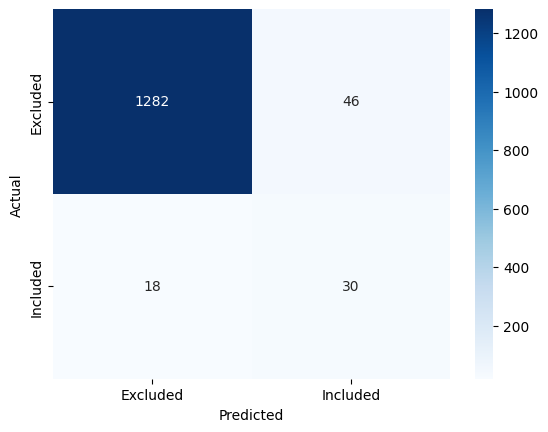

In [19]:
plot_confusion_matrix(df_all)

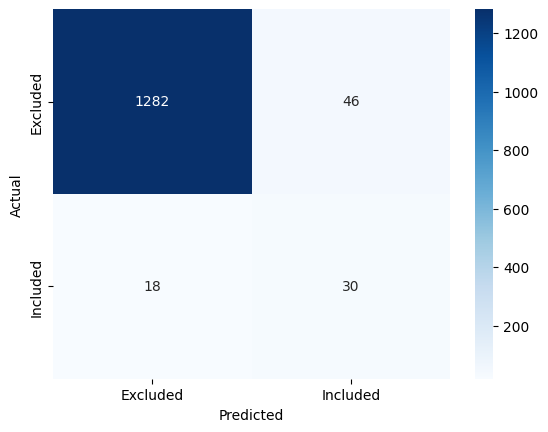

In [20]:
import os
os.makedirs('figures', exist_ok=True)
def plot_confusion_matrix(df, dpi=500):
    plt.figure()
    plt.tight_layout()
    cm = pd.crosstab(df['tag'], df['decision'], rownames=['Actual'], colnames=['Predicted'])
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues')
    plt.savefig('figures/confusion_matrix.png', dpi=dpi)
    plt.show()
plot_confusion_matrix(df_all)

In [21]:
df_all.shape[0]

1376

In [22]:
df_all.tag.value_counts()

tag
Excluded    1328
Included      48
Name: count, dtype: int64